# CodeNarrator : Explaining Python Errors with LSTM Encoder–Decoder Models

## Project Goal

The goal of CodeNarrator is to generate a short English explanation from a Python traceback using neural text generation.

We implement and compare two models from scratch in PyTorch:

1. **Baseline:** A bidirectional LSTM encoder with an LSTM decoder that uses the encoder's final state.
2. **Attention model:** The same architecture with **Bahdanau attention**, allowing the decoder to focus on different input tokens while generating an explanation.

We do not use pretrained models, Transformers or external APIs.

**Research question:** Does adding attention improve the quality of generated explanations?

## Notebook Organization

This notebook contains the main implementation, including preprocessing, model architectures, training, inference and evaluation.

It uses CSV files from `dataset/` and saved models from `../checkpoints/`. Existing checkpoints are loaded when available. To train the models again, set `FORCE_RETRAIN = True`.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Dataset exploration |
| 3 | Preprocessing and vocabulary |
| 4 | Copy-slot mechanism |
| 5–8 | Encoder, decoder, attention and Seq2Seq |
| 9 | Data preparation and training |
| 10–11 | Baseline and attention experiments |
| 12 | Evaluation and comparison |
| 13 | Visualizations |
| 14 | Inference examples |
| 15 | Results, limitations and conclusion |

## Dataset

We use a **synthetic dataset** generated from 104 error families, with 11 additional families held out for testing.

Since the data is synthetic, good results on the test sets do not guarantee that the models will work reliably on real-world Python errors.

**Note:** The models were trained previously, and their weights and training histories were saved as checkpoints. By default, the notebook loads these checkpoints instead of retraining the models, which explains why training logs are not displayed. The saved models are then evaluated on the datasets to reproduce the results. To train the models again and display epoch-by-epoch progress, set `FORCE_RETRAIN = True`.

##  Bonus : Interactive Web Application

Beyond the notebook, I developed a **web application using React and FastAPI** to demonstrate the trained attention model in practice.

### ✨ Features

-  **Error explanation:** Paste a Python traceback and generate a short explanation.
-  **Attention visualization:** Highlight the input tokens the model focuses on.
-  **Inference statistics:** Display response time and token information.
-  **Local inference:** Run the saved attention model on CPU without external AI APIs.

**Tech stack:** `React` · `FastAPI` · `PyTorch`

**Purpose:** Make the model accessible through a simple, interactive interface.

---

<div align="center">

*CodeNarrator — Understanding Python errors through neural text generation.*

</div>

## 1. Setup

In [ ]:
import torch
import os, sys, re, json, glob, time, math, random, copy, collections
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Paths
DATASET_DIR = "dataset"
CKPT_DIR = "../checkpoints"
RESULTS_DIR = "../results/notebook"

# Training settings
FORCE_RETRAIN = False
SEEDS = [42, 43, 44]

# Create folder for plots
os.makedirs(f"{RESULTS_DIR}/figures", exist_ok=True)

# Use GPU for training if available, otherwise CPU
device = torch.device(
    "cuda" if (FORCE_RETRAIN and torch.cuda.is_available()) else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Python:", sys.version.split()[0])

# Available checkpoints
print("Checkpoints:", sorted(
    os.path.relpath(p, CKPT_DIR)
    for p in glob.glob(f"{CKPT_DIR}/**/*.pt", recursive=True)
))

device: cpu | torch 2.12.0+cu126 | python 3.11.4
checkpoints found: ['attention_seed42.pt', 'attention_seed43.pt', 'attention_seed44.pt', 'baseline_seed42.pt', 'baseline_seed43.pt', 'baseline_seed44.pt', 'budget60\\attention_seed42.pt', 'budget60\\attention_seed43.pt', 'budget60\\attention_seed44.pt', 'budget60\\baseline_seed42.pt', 'budget60\\baseline_seed43.pt', 'budget60\\baseline_seed44.pt', 'budget60\\codenarrator_best.pt', 'codenarrator_best.pt', 'experiments\\baseline_seed43_60ep_patience12.pt', 'experiments\\baseline_seed43_src48.pt']


## 2. Dataset Loading and Exploration

We use five CSV files in this project, each with a different purpose.

- `train.csv`: Used to train the model and build the vocabulary.
- `validation.csv`: Used to check the model after each epoch, select the best version and avoid overfitting.
- `test.csv`: Used to evaluate the model on new examples of error types already seen during training.
- `test_novel_entities.csv`: Tests whether the model can preserve new names (files, variables, functions, etc.) that were not seen during training.
- `test_unseen_families.csv`: Tests how the model handles 11 error families that were never seen during training.

The first three files follow the usual train/validation/test split. We added two extra test sets to see how well the model handles unknown names and completely new error types.


In [ ]:
# Load datasets
files = {
    "train": "train",
    "validation": "validation",
    "test": "test",
    "test_novel": "test_novel_entities",
    "test_unseen": "test_unseen_families"
}
D = {}
for name, filename in files.items():
    D[name] = pd.read_csv(f"{DATASET_DIR}/{filename}.csv")

# Dataset statistics
print(pd.DataFrame({
    "rows": {k: len(d) for k, d in D.items()},
    "families": {k: d.scenario_id.nunique() for k, d in D.items()},
    "distinct targets": {k: d.target_text.nunique() for k, d in D.items()}
}))

print("\ncolumns:", list(D["train"].columns))
D["train"].head(3)

             rows  families  distinct targets
train        8320       104              1349
validation   1560       104               479
test         1560       104               486
test_novel    832       104               287
test_unseen   880        11                81

columns: ['id', 'split', 'category', 'exception_type', 'scenario_id', 'source', 'input_text', 'target_text', 'entities']


,id,split,category,exception_type,scenario_id,source,input_text,target_text,entities
0,TR-05804,train,database,psycopg2.errors.DeadlockDetected,F073,synthetic,"Traceback (most recent call last):\n File ""se...",The database transaction failed because a dead...,NaN
1,TR-02688,train,lookup,IndexError,F034,synthetic,"Traceback (most recent call last):\n File ""co...",The application attempted to access a characte...,NaN
2,TR-03474,train,imports,ImportError,F044,synthetic,"Traceback (most recent call last):\n File ""/h...",The application could not import customer_id f...,customer_id|pymongo


In [ ]:
# Check missing values and duplicates
allrows = pd.concat(D.values())

missing = int(allrows[["input_text", "target_text"]].isna().sum().sum())
duplicates = int(allrows.input_text.duplicated().sum())

print("missing input/target:", missing,
      "| duplicate inputs in the whole dataset:", duplicates)

# Check overlap with training data
tr_inputs = set(D["train"].input_text)

for k in ["validation", "test", "test_novel", "test_unseen"]:
    overlap = len(set(D[k].input_text) & tr_inputs)
    print(f"inputs of {k:12s} that also occur in train: {overlap}")

# Check error families
fam = {}
for k, d in D.items():
    fam[k] = set(d.scenario_id)
print("unseen test families that occur in train:",
      len(fam["test_unseen"] & fam["train"]),
      "| validation/test families are a subset of train families:",
      fam["validation"] <= fam["train"] and fam["test"] <= fam["train"])

# Check exception types
tr_exc = set(D["train"].exception_type)

print("exception types: train", len(tr_exc),
      "| in unseen-family test but not in train:",
      sorted(set(D["test_unseen"].exception_type) - tr_exc))

# Check exception types used in multiple scenarios
amb = D["train"].groupby("exception_type").scenario_id.nunique()
amb = amb.sort_values(ascending=False)

print("\nexception names shared by several families (the name alone does not determine the summary):")
print(amb[amb > 1].head(8).to_string())

missing input/target: 0 | duplicate inputs in the whole dataset: 0
inputs of validation   that also occur in train: 0
inputs of test         that also occur in train: 0
inputs of test_novel   that also occur in train: 0
inputs of test_unseen  that also occur in train: 0
unseen test families that occur in train: 0 | validation/test families are a subset of train families: True
exception types: train 61 | in unseen-family test but not in train: ['asyncio.exceptions.InvalidStateError']

exception names shared by several families (the name alone does not determine the summary):
exception_type
ValueError                       12
TypeError                         8
requests.exceptions.HTTPError     5
RuntimeError                      5
OSError                           4
json.decoder.JSONDecodeError      4
KeyError                          3
sqlite3.OperationalError          3


In [ ]:
#3 examples from different scenarios
examples = D["train"].drop_duplicates("scenario_id").sample(3, random_state=3)

for _, r in examples.iterrows():
    print(f"--- {r.category} / {r.exception_type} ({r.scenario_id})")
    print(r.input_text)
    print(f"=> {r.target_text}\n")

--- imports / IndentationError (F047)
ERROR [api] Request failed
Traceback (most recent call last):
  File "/home/dev/project/pipeline.py", line 13, in run_script
    return run_script(x)
IndentationError: expected an indented block after 'if' statement
=> Python could not run the script because a block is not indented.

--- types_values / OverflowError (F027)
Traceback (most recent call last):
  File "db.py", line 106, in save_request
    compute_score(data)
  File "/app/pipeline.py", line 233, in compute_score
    x ** y
OverflowError: math range error
=> The mathematical calculation produced a value outside the supported numeric range.

--- lookup / KeyError (F031)
Traceback (most recent call last):
  File "handlers.py", line 301, in <module>
    filter_rows(data)
  File "tasks.py", line 285, in filter_rows
    data["token"]
KeyError: 'token'
=> The pandas operation failed because column token is missing.



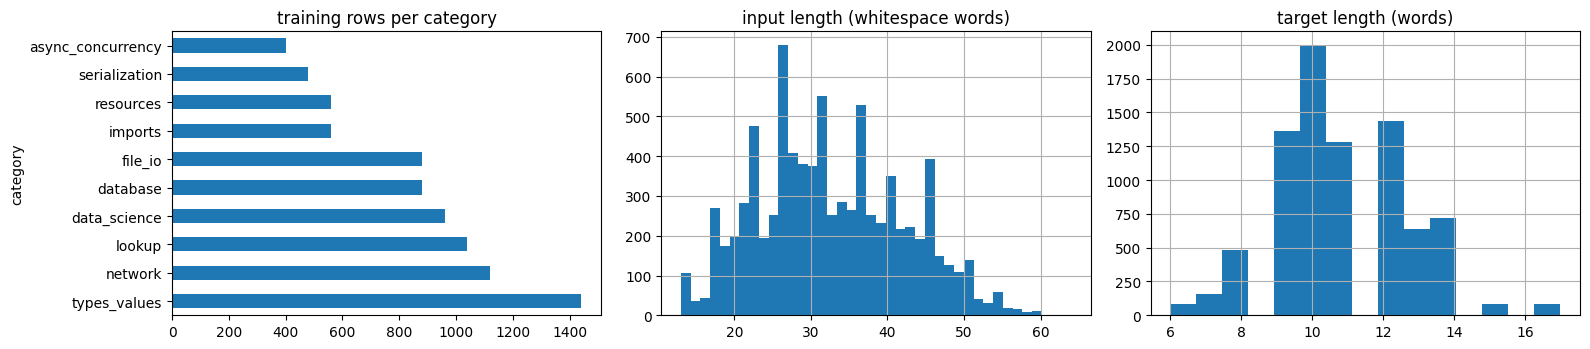

In [ ]:
# Dataset visualization
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))

# Number of examples per category
D["train"].category.value_counts().plot.barh(
    ax=ax[0], title="training rows per category")

# Input length distribution
D["train"].input_text.str.split().str.len().hist(
    bins=40, ax=ax[1])
ax[1].set_title("input length (whitespace words)")

# Target length distribution
D["train"].target_text.str.split().str.len().hist(
    bins=15, ax=ax[2])
ax[2].set_title("target length (words)")

plt.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/dataset_overview.png", dpi=130)
plt.show()

**Dataset limitations.** Every summary is a deterministic function of the error family and its slot values; the filler wording is a small vocabulary; tracebacks are illustrative.
High scores on the familiar sets therefore partly measure *template learning*, which is why the novel-identifier set and the unseen-family set exist.

## 3. Preprocessing and vocabulary
* **Source tokens**: case is kept (`KeyError` ≠ `keyerror`); dotted names are split at `.` (`customers . csv`); line breaks become `<NL>`; line numbers inside `File "x.py", line 123` become `<LN>` (random noise that never appears in a target); indentation is dropped. Numbers inside error messages are kept.
* **Target tokens**: whitespace split, dots and trailing commas detached; the mapping is exactly reversible (verified on every dataset file in the tests), which Exact Match needs.
* **Vocabularies** are built from `train.csv` only. Special tokens: `<PAD>`=0, `<UNK>`, `<SOS>`, `<EOS>`, then five copy-slot tokens.
* **Inference adapter**: the model only ever saw full tracebacks, so a bare line such as `KeyError: 'x'` is wrapped in the standard header before encoding (measured effect: `results/input_format_check.csv`).

In [ ]:

# Text preprocessing: traceback -> summary
import re

# Regular expressions
LINE_NO_RE = re.compile(r'(File "[^"]*", line )\d+')
SRC_TOKEN_RE = re.compile(r"<NL>|<LN>|[\w’]+|[^\w\s]")
FRAME_PREFIX_RE = re.compile(r"[ \t]+")

def normalize_source(text: str, normalize_line_numbers: bool = True) -> str:
    """Normalize traceback text before tokenization."""
    text = str(text).replace("\r\n", "\n").strip()

    if normalize_line_numbers:
        text = LINE_NO_RE.sub(r"\1<LN>", text)

    lines = [FRAME_PREFIX_RE.sub(" ", ln.strip()) for ln in text.split("\n")]
    return " <NL> ".join(ln for ln in lines if ln)

def tokenize_source(text: str, normalize_line_numbers: bool = True) -> list:
    """Tokenize the traceback."""
    return SRC_TOKEN_RE.findall(normalize_source(text, normalize_line_numbers))

def tokenize_target(text: str) -> list:
    """Tokenize the expected summary."""
    tokens = []

    for chunk in str(text).strip().split():
        trailing_comma = chunk.endswith(",") and len(chunk) > 1

        if trailing_comma:
            chunk = chunk[:-1]

        parts = re.split(r"(\.)", chunk)
        tokens.extend(p for p in parts if p != "")

        if trailing_comma:
            tokens.append(",")

    return tokens

def detokenize_target(tokens: list) -> str:
    """Convert tokens back into a sentence."""
    out, glue_next = "", False

    for i, tok in enumerate(tokens):
        last = i == len(tokens) - 1

        if tok == "," or (tok == "." and out):
            out += tok
            glue_next = tok == "." and not last
        else:
            out += ("" if (glue_next or not out) else " ") + tok
            glue_next = False

    return out


HEADER = "Traceback (most recent call last):"
_EXC_LINE = re.compile(r"^([A-Za-z_][\w.]*)(?::|$)")

def ensure_traceback_header(text):
    """Add the traceback header if it is missing."""
    text = str(text).strip()
    return text if HEADER in text else HEADER + "\n" + text

def exception_name(text):
    """Extract the exception name from the last line."""
    lines = [ln.strip() for ln in str(text).strip().split("\n") if ln.strip()]
    m = _EXC_LINE.match(lines[-1]) if lines else None
    return m.group(1) if m else None

def clean_dataframe(df):
    """Remove missing, empty and duplicate examples."""
    report = {"rows_in": len(df)}

    df = df.dropna(subset=["input_text", "target_text"])
    df = df[(df["input_text"].str.strip() != "") & (df["target_text"].str.strip() != "")]
    report["after_missing_or_empty"] = len(df)

    df = df.drop_duplicates(subset=["input_text", "target_text"])
    report["after_exact_duplicates"] = len(df)

    return df.reset_index(drop=True), report


In [ ]:

from collections import Counter

# Special tokens
PAD, UNK, SOS, EOS = "<PAD>", "<UNK>", "<SOS>", "<EOS>"
SPECIALS = [PAD, UNK, SOS, EOS]

class Vocabulary:
    def __init__(self, itos=None):
        self.itos = list(itos) if itos else list(SPECIALS)
        self.stoi = {t: i for i, t in enumerate(self.itos)}

    @classmethod
    def build(cls, token_lists, min_freq=2, max_size=None, extra=()):
        counts = Counter(t for toks in token_lists for t in toks)

        words = [
            t for t, c in sorted(counts.items(), key=lambda x: (-x[1], x[0]))
            if c >= min_freq and t not in SPECIALS and t not in extra]

        if max_size:
            words = words[: max_size - len(SPECIALS)]

        return cls(SPECIALS + list(extra) + words)

    def __len__(self):
        return len(self.itos)

    pad_id = property(lambda s: 0)
    unk_id = property(lambda s: 1)
    sos_id = property(lambda s: 2)
    eos_id = property(lambda s: 3)

    def encode(self, tokens, add_sos=False, add_eos=False, max_len=None):
        budget = None if max_len is None else max_len - int(add_sos) - int(add_eos)
        truncated = budget is not None and len(tokens) > budget

        if truncated:
            tokens = tokens[:budget]
        ids = [self.stoi.get(t, self.unk_id) for t in tokens]

        if add_sos:
            ids = [self.sos_id] + ids

        if add_eos:
            ids = ids + [self.eos_id]

        return ids, truncated

    def decode(self, ids, stop_at_eos=True):
        out = []
        for i in ids:
            i = int(i)

            if i == self.eos_id and stop_at_eos:
                break
            if i in (self.pad_id, self.sos_id):
                continue

            out.append(self.itos[i])

        return out

    def state(self):
        return list(self.itos)

In [ ]:
# Tokenization example
ex = D["train"].input_text.iloc[0]
print(ex, "\n")

print("source tokens:", tokenize_source(ex)[:30], "...")
print("target tokens:", tokenize_target(D["train"].target_text.iloc[0]))
print("bare line  ->", repr(ensure_traceback_header("KeyError: 'username'")))

Traceback (most recent call last):
  File "service.py", line 199, in handle_batch
    result = merge_user(records)
  File "utils.py", line 188, in merge_user
    return handle_user(x)
  File "handlers.py", line 295, in handle_user
    out = update_balance(batch)
  File "io_utils.py", line 53, in update_balance
    conn.commit()
    ^^^^^^^^^^^^^
psycopg2.errors.DeadlockDetected: deadlock detected 

source tokens: ['Traceback', '(', 'most', 'recent', 'call', 'last', ')', ':', '<NL>', 'File', '"', 'service', '.', 'py', '"', ',', 'line', '<LN>', ',', 'in', 'handle_batch', '<NL>', 'result', '=', 'merge_user', '(', 'records', ')', '<NL>', 'File'] ...
target tokens: ['The', 'database', 'transaction', 'failed', 'because', 'a', 'deadlock', 'was', 'detected', '.']
bare line  -> "Traceback (most recent call last):\nKeyError: 'username'"


## 4. Copy-slot Mechanism

One problem with our LSTM model is that it can only generate words from its vocabulary. However, Python errors often contain specific names, such as file names, variables or database columns, that were not seen during training.

o handle this, we use a simple copy-slot mechanism. Unknown words in the error message are replaced with tokens like <S1>, <S2>, and restored after prediction.

For example: revenue → <S1> → revenue.

During training, we randomly replace some entity names with slots (0.5 probability) so the model learns to preserve unseen names in its explanations.

In [ ]:

import re

# Copy slots for unknown words
N_SLOTS = 5
SLOT_TOKENS = [f"<S{i}>" for i in range(1, N_SLOTS + 1)]
_CANDIDATE = re.compile(r"(?=.*[A-Za-z])\w+$")

def last_line_start(tokens):
    # Find the beginning of the exception line
    return len(tokens) - tokens[::-1].index("<NL>") if "<NL>" in tokens else 0

def message_region(tokens):
    # Get the positions of words in the error message
    start = last_line_start(tokens)
    last = tokens[start:]

    return range(start + last.index(":") + 1, len(tokens)) if ":" in last else range(0)

def slot_map(tokens, vocab, mask_words=()):
    # Assign slots to unknown or masked words
    mapping = {}
    for i in message_region(tokens):
        w = tokens[i]

        if w in mapping or not _CANDIDATE.match(w) or len(mapping) >= N_SLOTS:
            continue

        if w in mask_words or w not in vocab.stoi:
            mapping[w] = SLOT_TOKENS[len(mapping)]

    return mapping

def apply_map(tokens, mapping):
    # Replace words with their slots
    return [mapping.get(t, t) for t in tokens]

def restore(tokens, mapping):
    # Replace slots with the original words
    inverse = {s: w for w, s in mapping.items()}
    return [inverse.get(t, "<UNK>" if t in SLOT_TOKENS else t) for t in tokens]


In [ ]:
# Copy-slot example
tb = 'Traceback (most recent call last):\n  File "report.py", line 41, in build\n    row["revenue"]\nKeyError: \'revenue\''
toks = tokenize_source(tb)

# Small vocabulary for testing
demo_vocab = Vocabulary(
    ["<PAD>", "<UNK>", "<SOS>", "<EOS>"] + SLOT_TOKENS +
    ["KeyError", ":", "The", "key", "is", "missing", "."])
mapping = slot_map(toks, demo_vocab)

print("slot map     :", mapping)
print("encoder input:", apply_map(toks, mapping)[-8:])
# Example decoder output
decoder_output = ["The", "key", "<S1>", "is", "missing", "."]

print("restored     :", detokenize_target(restore(decoder_output, mapping)))

slot map     : {'revenue': '<S1>'}
encoder input: ['"', ']', '<NL>', 'KeyError', ':', "'", '<S1>', "'"]
restored     : The key revenue is missing.


## 5. Bidirectional LSTM Encoder

We use an embedding layer (128) followed by a bidirectional LSTM (256 hidden units per direction).
The encoder reads the input in both directions and produces 512-dimensional outputs. Its final states are combined and reduced to 256 dimensions to initialize the decoder.

We use `pack_padded_sequence` to ignore padding tokens.

In [ ]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class Encoder(nn.Module):
    # Bidirectional LSTM encoder used by both models
    def __init__(self, vocab_size, emb_dim, hidden, dec_hidden,
                 num_layers=1, bidirectional=True, dropout=0.3, pad_id=0):

        super().__init__()

        self.num_layers, self.hidden, self.bi = num_layers, hidden, bidirectional
        self.enc_dim = hidden * (2 if bidirectional else 1)

        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)

        self.lstm = nn.LSTM(
            emb_dim, hidden, num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0)

        self.drop = nn.Dropout(dropout)

        # Convert encoder states to decoder size
        self.bridge_h = nn.Linear(self.enc_dim, dec_hidden)
        self.bridge_c = nn.Linear(self.enc_dim, dec_hidden)

    def _merge_directions(self, s):
        # Combine forward and backward states
        L, D = self.num_layers, 2 if self.bi else 1
        s = s.view(L, D, s.size(1), self.hidden)
        return torch.cat([s[:, d] for d in range(D)], dim=-1)

    def forward(self, src, src_len):
        # Embed input tokens
        emb = self.drop(self.embedding(src))

        # Ignore padding during LSTM processing
        packed = pack_padded_sequence(
            emb, src_len.cpu(), batch_first=True, enforce_sorted=False)

        out, (h, c) = self.lstm(packed)

        out, _ = pad_packed_sequence(
            out, batch_first=True, total_length=src.size(1))

        # Prepare initial decoder states
        h = torch.tanh(self.bridge_h(self._merge_directions(h)))
        c = torch.tanh(self.bridge_c(self._merge_directions(c)))

        return out, (h, c)

## 6. LSTM decoder
One step at a time: previous token → embedding → LSTM → linear layer over the target vocabulary (logits). With `use_attention=False` (baseline) the LSTM input is just the embedding. With `use_attention=True` the context vector of the attention module is concatenated to the LSTM input and to the output layer's input. The initial state comes from the encoder.

In [ ]:
import torch
import torch.nn as nn


class Decoder(nn.Module):
    # LSTM decoder with optional attention

    def __init__(self, vocab_size, emb_dim, hidden, enc_dim,
                 num_layers=1, dropout=0.3, use_attention=False,
                 attn_dim=128, pad_id=0):

        super().__init__()

        self.use_attention, self.num_layers = use_attention, num_layers
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)

        self.attention = (
            BahdanauAttention(enc_dim, hidden, attn_dim)
            if use_attention else None)

        self.lstm = nn.LSTM(
            emb_dim + (enc_dim if use_attention else 0),
            hidden,
            num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0)

        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(
            hidden + (enc_dim if use_attention else 0),
            vocab_size)

    def step(self, token, state, enc_out=None, mask=None):
        # Embed the previous token
        x = self.drop(self.embedding(token))
        weights, ctx = None, None

        # Use attention if enabled
        if self.use_attention:
            ctx, weights = self.attention(state[0][-1], enc_out, mask)
            x = torch.cat([x, ctx], dim=-1)

        # Predict the next token
        o, state = self.lstm(x.unsqueeze(1), state)
        o = o.squeeze(1)

        feat = torch.cat([o, ctx], dim=-1) if self.use_attention else o

        return self.out(self.drop(feat)), state, weights

## 7. Bahdanau Attention

We use Bahdanau attention to help the decoder focus on important parts of the traceback when generating each word.

The attention is calculated as follows:

`score_j = vᵀ · tanh(W_h h_j + W_s s)` → `α = softmax(score)` (padding positions set to −∞ first) → `context = Σ_j α_j h_j`

The scores determine how much attention each input token receives. The context vector combines the important information.

Unlike the baseline, the decoder can look at the encoder outputs at every step instead of relying only on the final encoder states.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class BahdanauAttention(nn.Module):
    # Attention mechanism for the LSTM decoder

    def __init__(self, enc_dim, dec_hidden, attn_dim):
        super().__init__()

        self.W_h = nn.Linear(enc_dim, attn_dim, bias=False)
        self.W_s = nn.Linear(dec_hidden, attn_dim, bias=True)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, dec_state, enc_out, mask):
        # Calculate attention scores
        scores = self.v(
            torch.tanh(
                self.W_h(enc_out) + self.W_s(dec_state).unsqueeze(1))).squeeze(-1)

        # Ignore padding tokens
        scores = scores.masked_fill(~mask, float("-inf"))

        # Convert scores into attention weights
        weights = F.softmax(scores, dim=-1)

        # Combine encoder outputs using these weights
        context = torch.bmm(weights.unsqueeze(1), enc_out).squeeze(1)

        return context, weights

## 8. Seq2Seq Model: Teacher Forcing and Greedy Decoding

We use two methods for training and prediction:

- **`forward()` (training):** Uses teacher forcing. With `teacher_forcing_ratio = 1.0`, the decoder always receives the correct previous token during training.
- **`generate()` (evaluation):** Starts with `<SOS>` and uses its own predictions to generate the next tokens, until `<EOS>` or the maximum length is reached.

During evaluation, the model does not use the correct target text, so the predictions are independent of the reference.

In [ ]:
import random
import torch
import torch.nn as nn


class Seq2Seq(nn.Module):

    def __init__(self, src_vocab_size, tgt_vocab_size, cfg, use_attention):
        super().__init__()
        self.use_attention, self.cfg = use_attention, dict(cfg)

        # Create the encoder
        self.encoder = Encoder(
            src_vocab_size, cfg["emb_dim"], cfg["enc_hidden"],
            cfg["dec_hidden"], cfg["num_layers"],
            cfg["bidirectional"], cfg["dropout"])

        # Create the decoder
        self.decoder = Decoder(
            tgt_vocab_size, cfg["emb_dim"], cfg["dec_hidden"],
            self.encoder.enc_dim, cfg["num_layers"],
            cfg["dropout"], use_attention, cfg["attn_dim"])
        self.sos_id, self.eos_id, self.pad_id = 2, 3, 0

    def encode(self, src, src_len):
        # Encode the input and identify padding tokens
        enc_out, state = self.encoder(src, src_len)
        mask = src != self.pad_id
        return enc_out, state, mask

    def forward(self, src, src_len, tgt, teacher_forcing_ratio=1.0):
        # Training with teacher forcing
        enc_out, state, mask = self.encode(src, src_len)
        T = tgt.shape[1]
        inp, outs = tgt[:, 0], []

        for t in range(1, T):
            logits, state, _ = self.decoder.step(inp, state, enc_out, mask)
            outs.append(logits)
            # Use the correct token or the model prediction
            use_gold = random.random() < teacher_forcing_ratio
            inp = tgt[:, t] if use_gold else logits.argmax(-1)

        return torch.stack(outs, dim=1)

    @torch.no_grad()
    def generate(self, src, src_len, max_len=40, return_attention=False):
        # Generate predictions without the target text
        self.eval()
        enc_out, state, mask = self.encode(src, src_len)
        B = src.size(0)

        # Start with the SOS token
        inp = torch.full((B,), self.sos_id, dtype=torch.long, device=src.device)
        done = torch.zeros(B, dtype=torch.bool, device=src.device)
        ids, atts = [], []

        for _ in range(max_len):
            logits, state, w = self.decoder.step(inp, state, enc_out, mask)

            # Select the token with the highest score
            inp = logits.argmax(-1).masked_fill(done, self.pad_id)
            ids.append(inp)
            # Check if EOS was generated
            done = done | (inp == self.eos_id)

            if w is not None:
                atts.append(w)
            if done.all():
                break

        ids = torch.stack(ids, 1)
        if return_attention:
            return ids, (torch.stack(atts, 1) if atts else None)
        return ids

    def num_parameters(self):
        # Count trainable parameters
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

In [ ]:
# Test the model with random data
m = Seq2Seq(
    60, 50,
    dict( emb_dim=16, enc_hidden=24, dec_hidden=24, num_layers=1, bidirectional=True,
        dropout=0.0,attn_dim=16),use_attention=True)

# Create sample inputs with padding
src_ids = torch.randint(4, 60, (3, 9))
src_len = torch.tensor([9, 6, 4])

src_ids[1, 6:] = 0
src_ids[2, 4:] = 0

tgt_ids = torch.randint(4, 50, (3, 7))

# Check output dimensions
print(
    "logits:",
    tuple(m(src_ids, src_len, tgt_ids).shape),
    "= (batch, target_len-1, vocab)")

# Check attention and padding
enc_out, (h, c), mask = m.encode(src_ids, src_len)
ctx, w = m.decoder.attention(h[-1], enc_out, mask)

print(
    "attention weights sum to 1:", bool(torch.allclose(w.sum(1), torch.ones(3))),
    "| exactly 0 on padding:",
    bool((w[~mask] == 0).all()))

logits: (3, 6, 50) = (batch, target_len-1, vocab)
attention weights sum to 1: True | exactly 0 on padding: True


## 9. Data Pipeline, Training and Configuration

We prepare the data and train both models using the same settings.

- **Data preparation:** `Seq2SeqDataset` converts text into token IDs. During training, we randomly replace some entity names with copy slots and 15% of tokens outside the exception line with `<UNK>`. Evaluation data is not augmented.
- **Input length:** For long tracebacks, we keep the last tokens to preserve the exception message.
- **Training:** We use cross-entropy loss (ignoring `<PAD>`), Adam with a learning rate of `0.001`, and gradient clipping at `1.0`.
- **Early stopping:** Training stops when validation loss stops improving, and the best model weights are restored.

Both models use the same data, vocabulary, training settings and evaluation method for a fair comparison.

In [ ]:
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader


# Dataset files
CSV_FILES = {
    "train": "train",
    "val_familiar": "validation",
    "test_familiar": "test",
    "test_novel": "test_novel_entities",
    "test_unseen": "test_unseen_families"}


def load_splits(data_dir):
    # Load and clean the five datasets
    return {
        key: clean_dataframe(pd.read_csv(f"{data_dir}/{name}.csv"))[0]
        for key, name in CSV_FILES.items()}


class Seq2SeqDataset(Dataset):

    def __init__(self, df, src_vocab, tgt_vocab, max_src_len, max_tgt_len,
                 normalize_line_numbers=True, use_slots=False, train=False,
                 p_mask=0.5, p_unk=0.15, seed=0):

        self.df = df.reset_index(drop=True)
        self.sv, self.tv, self.max_src, self.max_tgt = (
            src_vocab, tgt_vocab, max_src_len, max_tgt_len)

        self.use_slots, self.train, self.p_mask, self.p_unk = (
            use_slots, train, p_mask, p_unk)

        self.rng = random.Random(seed)

        # Tokenize inputs and targets
        self.src_tokens = [
            tokenize_source(x, normalize_line_numbers)
            for x in self.df.input_text]

        self.tgt_tokens = [
            tokenize_target(x) for x in self.df.target_text]

        # Extract entity words
        ents = self.df["entities"].fillna("") if "entities" in self.df else [""] * len(self.df)

        self.entity_words = [
            {w for e in str(x).split("|") if e for w in tokenize_source(e)}
            for x in ents]

        # Count truncated sequences
        self.src_trunc = sum(len(t) > max_src_len for t in self.src_tokens)
        self.tgt_trunc = sum(len(t) + 2 > max_tgt_len for t in self.tgt_tokens)

        # Cache evaluation examples
        self.cache = None if train else [
            self._build(i, False) for i in range(len(self.df))]

        self.maps = None if train else [c[2] for c in self.cache]

    def _build(self, i, augment):
        # Prepare one example
        toks, tgt = self.src_tokens[i], self.tgt_tokens[i]
        mapping = {}

        # Replace unknown or masked entities with copy slots
        if self.use_slots:
            masked = {
                w for w in self.entity_words[i]
                if augment and self.rng.random() < self.p_mask}

            mapping = slot_map(toks, self.sv, masked)
            toks, tgt = apply_map(toks, mapping), apply_map(tgt, mapping)

        # Randomly replace tokens outside the exception line
        if augment and self.p_unk:
            start = last_line_start(toks)

            toks = [
                UNK if j < start and t not in SLOT_TOKENS
                and self.rng.random() < self.p_unk else t
                for j, t in enumerate(toks)]

        # Keep the end of long tracebacks
        toks = toks[-self.max_src:]

        # Convert tokens into IDs
        src_ids, _ = self.sv.encode(toks)
        tgt_ids, _ = self.tv.encode(
            tgt, add_sos=True, add_eos=True, max_len=self.max_tgt)

        return src_ids, tgt_ids, mapping

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        # Apply augmentation only during training
        src_ids, tgt_ids, _ = self._build(i, True) if self.train else self.cache[i]
        return src_ids, tgt_ids, i


def collate(batch):
    # Pad sequences to the longest one in each batch
    srcs, tgts, idx = zip(*batch)

    src_len = torch.tensor([len(s) for s in srcs])
    src = torch.zeros(len(srcs), int(src_len.max()), dtype=torch.long)
    tgt = torch.zeros(len(tgts), max(len(t) for t in tgts), dtype=torch.long)

    for i, (s, t) in enumerate(zip(srcs, tgts)):
        src[i, : len(s)] = torch.tensor(s)
        tgt[i, : len(t)] = torch.tensor(t)

    return src, src_len, tgt, torch.tensor(idx)


def make_loader(ds, batch_size, shuffle, seed=0):
    # Create a DataLoader with a fixed seed
    g = torch.Generator()
    g.manual_seed(seed)

    return DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle,
        collate_fn=collate, generator=g)


def build_vocabs(train_df, min_freq_src=2, min_freq_tgt=1,
                 normalize_line_numbers=True, use_slots=False):
    # Build vocabularies using training data only
    extra = tuple(SLOT_TOKENS) if use_slots else ()

    sv = Vocabulary.build(
        [tokenize_source(x, normalize_line_numbers) for x in train_df.input_text],
        min_freq_src, extra=extra)

    tv = Vocabulary.build(
        [tokenize_target(x) for x in train_df.target_text],
        min_freq_tgt, extra=extra)

    return sv, tv

In [ ]:
import time
import random
import math
import copy
import numpy as np
import torch
import torch.nn as nn

# Training configuration
DEFAULT_CONFIG = dict(emb_dim=128,
    enc_hidden=256,
    dec_hidden=256,
    num_layers=1,
    bidirectional=True,
    dropout=0.3,
    attn_dim=128,
    batch_size=64,
    lr=1e-3,
    epochs=30,
    patience=5,
    clip=1.0,
    teacher_forcing=1.0,
    max_src_len=192,
    max_tgt_len=32,
    min_freq_src=2,
    min_freq_tgt=1,
    normalize_line_numbers=True,
    use_slots=True,
    p_mask=0.5,
    p_unk=0.15,
    select_on="familiar")

def set_seed(seed):
    # Set random seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def eval_loss(model, loader, criterion, device):
    # Calculate validation loss without updating the model
    model.eval()
    tot, n = 0.0, 0

    for src, src_len, tgt, _ in loader:
        src, src_len, tgt = src.to(device), src_len.to(device), tgt.to(device)

        logits = model(src, src_len, tgt, teacher_forcing_ratio=1.0)
        gold = tgt[:, 1:]

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            gold.reshape(-1))
        k = (gold != 0).sum().item()
        tot += loss.item() * k
        n += k

    return tot / n

def train_model(model, loaders, cfg, device, tag="model", log_fn=print, quick_eval=None):
    # Train the model and keep the best weights

    criterion = nn.CrossEntropyLoss(ignore_index=0, reduction="mean")
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    # Choose which validation loss to monitor
    key = "val_familiar_loss" if cfg["select_on"] == "familiar" else "val_heldout_loss"

    best, best_state, bad, hist, t0 = float("inf"), None, 0, [], time.time()

    for ep in range(1, cfg["epochs"] + 1):
        model.train()
        tot, n = 0.0, 0

        for src, src_len, tgt, _ in loaders["train"]:
            src, src_len, tgt = src.to(device), src_len.to(device), tgt.to(device)

            # Forward pass
            logits = model(
                src, src_len, tgt,
                teacher_forcing_ratio=cfg["teacher_forcing"])

            gold = tgt[:, 1:]

            # Calculate loss
            loss = criterion( logits.reshape(-1, logits.size(-1)),
                gold.reshape(-1))

            # Update model weights
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            opt.step()

            k = (gold != 0).sum().item()
            tot += loss.item() * k
            n += k

        # Evaluate after each epoch
        row = {
            "epoch": ep,
            "train_loss": tot / n,
            "val_familiar_loss": eval_loss(
                model, loaders["val_familiar"], criterion, device
            ),
            "val_heldout_loss": eval_loss(
                model, loaders["val_heldout"], criterion, device
            ) if loaders.get("val_heldout") else 0.0,
            "time_s": time.time() - t0}

        if quick_eval:
            row.update(quick_eval(model))

        hist.append(row)

        # Save the best model state
        improved = row[key] < best - 1e-4

        if improved:
            best, bad, best_state = row[key], 0, copy.deepcopy(model.state_dict())
            row["best"] = True
        else:
            bad += 1

        # Display training progress
        log_fn(
            f"[{tag}] ep {ep:02d} train {row['train_loss']:.4f} "
            f"| val_fam {row['val_familiar_loss']:.4f} "
            f"| val_heldout {row['val_heldout_loss']:.4f}"
            + (f" | fam_EM {row['val_familiar_em']:.1f}" if quick_eval else "")
            + (" *" if improved else ""))

        # Stop if validation loss does not improve
        if bad >= cfg["patience"]:
            log_fn(f"[{tag}] early stopping at epoch {ep}")
            break

    # Restore the best weights
    model.load_state_dict(best_state)

    return model, hist


def save_checkpoint(path, model, cfg, src_vocab, tgt_vocab,
                    use_attention, history=None, extra=None):
    # Save the model, configuration and vocabularies
    torch.save(
        {
            "model_state": model.state_dict(),
            "config": dict(cfg),
            "use_attention": use_attention,
            "src_vocab": src_vocab.state(),
            "tgt_vocab": tgt_vocab.state(),
            "history": history,
            "extra": extra or {}
        },
        path)

In [ ]:
import re
import math
import collections
import numpy as np
import torch


# Tokenize text for evaluation
_W = re.compile(r"[a-z0-9]+")
_rtok = lambda s: _W.findall(s.lower())


def _f1(overlap, n_pred, n_ref):
    # Calculate F1 score
    if overlap == 0:
        return 0.0

    p, r = overlap / n_pred, overlap / n_ref
    return 2 * p * r / (p + r)


def _ngrams(toks, n):
    # Count groups of n consecutive tokens
    return collections.Counter(
        tuple(toks[i:i + n]) for i in range(len(toks) - n + 1)
    )


def rouge_n(pred, ref, n):
    # Calculate ROUGE-1 or ROUGE-2
    p, r = _ngrams(_rtok(pred), n), _ngrams(_rtok(ref), n)

    return (
        _f1(sum((p & r).values()), sum(p.values()), sum(r.values()))
        if p and r else 0.0
    )


def _lcs(a, b):
    # Find the longest common subsequence
    prev = [0] * (len(b) + 1)

    for x in a:
        cur = [0]

        for j, y in enumerate(b):
            cur.append(
                prev[j] + 1 if x == y else max(prev[j + 1], cur[j])
            )

        prev = cur

    return prev[-1]


def rouge_l(pred, ref):
    # Calculate ROUGE-L
    p, r = _rtok(pred), _rtok(ref)

    return _f1(_lcs(p, r), len(p), len(r)) if p and r else 0.0


def bleu(preds, refs, max_n=4):
    # Calculate corpus BLEU-4
    clipped, total, plen, rlen = [0] * max_n, [0] * max_n, 0, 0

    for p, r in zip(preds, refs):
        p, r = _rtok(p), _rtok(r)
        plen, rlen = plen + len(p), rlen + len(r)

        for n in range(1, max_n + 1):
            pg, rg = _ngrams(p, n), _ngrams(r, n)
            clipped[n - 1] += sum((pg & rg).values())
            total[n - 1] += sum(pg.values())

    if plen == 0 or min(clipped) == 0:
        return 0.0

    brevity = 1.0 if plen > rlen else math.exp(1 - rlen / plen)

    return 100 * brevity * math.exp(
        sum(math.log(c / t) for c, t in zip(clipped, total)) / max_n
    )


@torch.no_grad()
def generate_dataset(model, ds, tgt_vocab, device, batch_size=128, max_len=40):
    # Generate predictions for the whole dataset
    model.eval()
    preds = [None] * len(ds)

    for src, src_len, _, idx in make_loader(ds, batch_size, shuffle=False):
        ids = model.generate(
            src.to(device), src_len.to(device), max_len=max_len
        ).cpu()

        for k, row in zip(idx.tolist(), ids):
            toks = tgt_vocab.decode(row.tolist())

            # Restore copied entity names
            if ds.maps is not None and ds.maps[k]:
                toks = restore(toks, ds.maps[k])

            preds[k] = detokenize_target(toks)

    return preds


def entity_recall(pred, ref, source, common):
    # Check how many important source details are preserved
    src = set(w.lower() for w in tokenize_source(source))

    ents = [
        w.lower() for w in tokenize_target(ref)
        if w.lower() in src and w.lower() not in common and w.isalnum()
    ]

    if not ents:
        return None

    pset = set(w.lower() for w in tokenize_target(pred))

    return float(np.mean([e in pset for e in ents]))


def score(preds, df, common=frozenset()):
    # Calculate all evaluation metrics
    refs, srcs = df.target_text.tolist(), df.input_text.tolist()

    r1 = [rouge_n(p, r, 1) for p, r in zip(preds, refs)]
    r2 = [rouge_n(p, r, 2) for p, r in zip(preds, refs)]
    rl = [rouge_l(p, r) for p, r in zip(preds, refs)]

    em = [
        float(p.strip() == r.strip())
        for p, r in zip(preds, refs)
    ]

    # Compare tokens at the same positions
    tacc = []

    for p, r in zip(preds, refs):
        pt, rt = tokenize_target(p), tokenize_target(r)
        tacc.append(
            sum(a == b for a, b in zip(pt, rt)) / max(len(rt), 1)
        )

    er = [
        entity_recall(p, r, s, common)
        for p, r, s in zip(preds, refs, srcs)
    ]

    er = [x for x in er if x is not None]

    return {
        "rouge1": 100 * np.mean(r1),
        "rouge2": 100 * np.mean(r2),
        "rougeL": 100 * np.mean(rl),
        "bleu": bleu(preds, refs),
        "exact_match": 100 * np.mean(em),
        "token_acc": 100 * np.mean(tacc),
        "entity_recall": 100 * np.mean(er) if er else float("nan"),
        "avg_pred_len": float(
            np.mean([len(tokenize_target(p)) for p in preds])
        )
    }


def common_target_words(train_df, top=40):
    # Find the most frequent words in training summaries
    c = collections.Counter(
        w.lower()
        for t in train_df.target_text
        for w in tokenize_target(t)
    )

    return frozenset(w for w, _ in c.most_common(top))

def per_group(preds, df, col):
    # Calculate ROUGE-L and Exact Match for each group
    rows = []
    d = df.assign(pred=preds)

    for key, g in d.groupby(col):
        rows.append({
            col: key,
            "n": len(g),
            "rougeL": 100 * np.mean([
                rouge_l(p, r)
                for p, r in zip(g.pred, g.target_text)
            ]),
            "exact_match": 100 * np.mean([
                p.strip() == r.strip()
                for p, r in zip(g.pred, g.target_text)
            ])})

    return rows

def template_regurgitation_rate(preds, train_df):
    # Check how often predictions copy training summaries
    known = set(train_df.target_text.str.strip())

    return 100 * float(
        np.mean([p.strip() in known for p in preds]))

def oracle_template_rougeL(refs, train_df):
    # Find the best possible ROUGE-L using only training summaries
    cands = sorted(set(train_df.target_text.str.strip()))
    cache = {}

    for r in set(refs):
        cache[r] = max(rouge_l(c, r) for c in cands)

    return 100 * float(np.mean([cache[r] for r in refs]))

In [ ]:
import time
import torch


def prepare_data(data_dir, cfg):
    # Load datasets and build vocabularies
    frames = load_splits(data_dir)
    use_slots = cfg.get("use_slots", False)

    sv, tv = build_vocabs(
        frames["train"],
        cfg["min_freq_src"],
        cfg["min_freq_tgt"],
        cfg["normalize_line_numbers"],
        use_slots
    )

    # Create a dataset for each split
    make = lambda split, df: Seq2SeqDataset(
        df, sv, tv,
        cfg["max_src_len"],
        cfg["max_tgt_len"],
        cfg["normalize_line_numbers"],
        use_slots=use_slots,
        train=(split == "train"),
        p_mask=cfg.get("p_mask", .5),
        p_unk=cfg.get("p_unk", .15)
    )

    ds = {split: make(split, df) for split, df in frames.items()}

    return dict(
        frames=frames,
        ds=ds,
        src_vocab=sv,
        tgt_vocab=tv,
        common=common_target_words(frames["train"])
    )


def make_loaders(data, cfg, seed):
    # Create training and validation loaders
    return {
        "train": make_loader(
            data["ds"]["train"], cfg["batch_size"], True, seed
        ),
        "val_familiar": make_loader(
            data["ds"]["val_familiar"], 256, False
        )
    }


def evaluate_model(model, data, device):
    # Generate predictions and calculate metrics
    results, preds = {}, {}

    for split in [k for k in data["ds"] if k != "train"]:
        preds[split] = generate_dataset(
            model, data["ds"][split], data["tgt_vocab"], device
        )

        results[split] = score(
            preds[split], data["frames"][split], data["common"]
        )

    return results, preds


def run_model(name, use_attention, seed, data, cfg, device,
              ckpt_dir=None, log_fn=print):
    # Train and evaluate one model
    set_seed(seed)

    model = Seq2Seq(
        len(data["src_vocab"]),
        len(data["tgt_vocab"]),
        cfg,
        use_attention
    ).to(device)

    n_params = model.num_parameters()
    loaders = make_loaders(data, cfg, seed)

    # Check validation predictions after each epoch
    def quick(m):
        p = generate_dataset(
            m, data["ds"]["val_familiar"], data["tgt_vocab"], device
        )

        s = score(
            p, data["frames"]["val_familiar"], data["common"]
        )

        return {
            "val_familiar_em": s["exact_match"],
            "val_familiar_rougeL": s["rougeL"]
        }

    # Train the model
    t0 = time.time()

    model, hist = train_model(
        model, loaders, cfg, device,
        tag=f"{name}-s{seed}",
        log_fn=log_fn,
        quick_eval=quick
    )

    train_time = time.time() - t0

    # Evaluate on all test and validation splits
    results, preds = evaluate_model(model, data, device)

    info = dict(
        name=name,
        seed=seed,
        use_attention=use_attention,
        params=n_params,
        train_time_s=train_time,
        epochs_run=len(hist),
        best_epoch=[r["epoch"] for r in hist if r.get("best")][-1],
        results=results
    )

    # Save checkpoint if a directory is provided
    if ckpt_dir:
        path = f"{ckpt_dir}/{name}_seed{seed}.pt"

        save_checkpoint(
            path, model, cfg,
            data["src_vocab"], data["tgt_vocab"],
            use_attention, hist, extra=info
        )

        info["checkpoint"] = path

    return model, hist, info, preds


def load_run(path, data, cfg, device):
    # Load an existing trained model
    model, sv, tv, ck = load_checkpoint(path, device)

    # Check vocabulary compatibility
    assert sv.itos == data["src_vocab"].itos and tv.itos == data["tgt_vocab"].itos, \
        f"{path}: vocabulary differs from the current dataset/config (retrain or fix the config)"

    # Check copy-slot configuration
    assert ck["config"].get("use_slots") == cfg.get("use_slots"), \
        f"{path}: trained with a different copy-slot setting"

    # Evaluate the loaded model
    info = dict(ck["extra"])
    info["checkpoint"] = path

    info["results"], preds = evaluate_model(model, data, device)

    return model, ck["history"], info, preds

In [ ]:
import sys
import torch


def load_checkpoint(path, device="cpu"):
    # Load a trained model and its vocabularies
    ck = torch.load(path, map_location=device, weights_only=False)

    # Check that the checkpoint contains the required data
    for key in ("model_state", "config", "use_attention", "src_vocab", "tgt_vocab"):
        if key not in ck:
            raise ValueError(f"{path} is not a CodeNarrator checkpoint (missing '{key}')")

    sv, tv = Vocabulary(ck["src_vocab"]), Vocabulary(ck["tgt_vocab"])

    # Recreate the model and load its weights
    model = Seq2Seq(
        len(sv), len(tv), ck["config"], ck["use_attention"]
    ).to(device)

    model.load_state_dict(ck["model_state"])
    model.eval()

    return model, sv, tv, ck


@torch.no_grad()
def summarize(model, sv, tv, cfg, traceback_text,
              device="cpu", return_attention=False, add_header=True):
    # Generate an explanation for one traceback

    if not str(traceback_text).strip():
        raise ValueError("empty traceback")

    # Add a traceback header if needed
    if add_header:
        traceback_text = ensure_traceback_header(traceback_text)

    # Tokenize the input
    toks = tokenize_source(
        traceback_text, cfg.get("normalize_line_numbers", True)
    )

    # Replace unknown words with copy slots
    mapping = slot_map(toks, sv) if cfg.get("use_slots") else {}

    # Keep the end of long tracebacks
    shown = toks[-cfg["max_src_len"]:]

    ids, _ = sv.encode(apply_map(shown, mapping))
    src = torch.tensor([ids], device=device)

    # Generate the explanation
    out = model.generate(
        src,
        torch.tensor([len(ids)], device=device),
        max_len=cfg["max_tgt_len"] + 8,
        return_attention=return_attention
    )

    if return_attention:
        out, att = out

    # Convert predicted IDs back into text
    text = detokenize_target(
        restore(tv.decode(out[0].tolist()), mapping)
    )

    n_unk = sum(i == sv.unk_id for i in ids)

    return (text, att, shown, n_unk) if return_attention else text


def input_warnings(text, sv):
    # Warn about unfamiliar or invalid exception types
    name = exception_name(text)

    if name is None:
        return ["The last line does not look like a Python exception line (expected 'ExceptionName: message')."]

    if name.split(".")[-1] not in sv.stoi:
        return [f"The model never saw the exception type {name} during training; the summary is probably wrong."]

    return []


class Summarizer:
    # Load the model once and reuse it for predictions

    def __init__(self, path, device="cpu"):
        self.path, self.device = str(path), device

        self.model, self.sv, self.tv, self.ck = load_checkpoint(
            self.path, device
        )

        self.cfg = self.ck["config"]

    def __call__(self, text, return_attention=False):
        # Generate a summary
        return summarize(
            self.model, self.sv, self.tv, self.cfg,
            text, self.device, return_attention
        )

    def warnings(self, text):
        # Check for possible input problems
        return input_warnings(text, self.sv)

In [ ]:
# Load experiment settings
cfg = dict(DEFAULT_CONFIG)
print(json.dumps(cfg, indent=1))

# Prepare datasets and vocabularies
data = prepare_data(DATASET_DIR, cfg)
sv, tv = data["src_vocab"], data["tgt_vocab"]

print("\nvocabulary sizes: source", len(sv), "| target", len(tv))

# Check dataset sizes and truncated sequences
for k, ds in data["ds"].items():
    print(
        f"{k:14s} n={len(ds):5d} "
        f"| sources longer than max_src_len ({cfg['max_src_len']}): {ds.src_trunc} "
        f"| targets truncated: {ds.tgt_trunc}"
    )

# Find test words missing from the training vocabulary
unseen_words = {
    w
    for t in pd.concat([D["test_novel"], D["test_unseen"]]).target_text
    for w in tokenize_target(t)
} - set(tv.stoi)

print(
    f"\ntarget words of the test sets that are NOT in the training vocabulary: "
    f"{len(unseen_words)} (e.g. {sorted(unseen_words)[:8]})"
)

# Compare the number of parameters
for name, att in [("baseline", False), ("attention", True)]:
    print(
        f"{name:10s} trainable parameters: "
        f"{Seq2Seq(len(sv), len(tv), cfg, att).num_parameters():,}"
    )

{
 "emb_dim": 128,
 "enc_hidden": 256,
 "dec_hidden": 256,
 "num_layers": 1,
 "bidirectional": true,
 "dropout": 0.3,
 "attn_dim": 128,
 "batch_size": 64,
 "lr": 0.001,
 "epochs": 30,
 "patience": 5,
 "clip": 1.0,
 "teacher_forcing": 1.0,
 "max_src_len": 192,
 "max_tgt_len": 32,
 "min_freq_src": 2,
 "min_freq_tgt": 1,
 "normalize_line_numbers": true,
 "use_slots": true,
 "p_mask": 0.5,
 "p_unk": 0.15,
 "select_on": "familiar"
}



vocabulary sizes: source 1361 | target 619
train          n= 8320 | sources longer than max_src_len (192): 0 | targets truncated: 0
val_familiar   n= 1560 | sources longer than max_src_len (192): 0 | targets truncated: 0
test_familiar  n= 1560 | sources longer than max_src_len (192): 0 | targets truncated: 0
test_novel     n=  832 | sources longer than max_src_len (192): 0 | targets truncated: 0
test_unseen    n=  880 | sources longer than max_src_len (192): 0 | targets truncated: 0

target words of the test sets that are NOT in the training vocabulary: 69 (e.g. ['7b', 'An', 'allocate', 'assignment', 'audit', 'audits', 'billing', 'build_data'])
baseline   trainable parameters: 1,860,971
attention  trainable parameters: 2,800,747


## 10. Baseline Training

We train the baseline model using different random seeds. If a checkpoint already exists, we load it and evaluate the model without retraining.

We compare two training configurations:

| Experiment | Max epochs | Early stopping patience |
|---|---|---|
| Main run | 30 | 5 |
| Extended run | 60 | 12 |

The extended run gives the baseline more time to learn.

When `FORCE_RETRAIN = True`, the model is trained again, and new checkpoints are saved separately in `../checkpoints/notebook_retrain/` to preserve the original results.

In [ ]:
# Define the two training protocols
PROTOCOLS = {
    "A (30 epochs, patience 5)": dict(
        dir=CKPT_DIR, epochs=30, patience=5
    ),
    "B (60 epochs, patience 12)": dict(
        dir=f"{CKPT_DIR}/budget60", epochs=60, patience=12)}
# Store the models and their results
RUNS = {}
def get_run(protocol, name, seed):
    p = PROTOCOLS[protocol]
    path = f"{p['dir']}/{name}_seed{seed}.pt"

    if FORCE_RETRAIN:
        # Train a new model and save it separately
        out_dir = f"{CKPT_DIR}/notebook_retrain/{protocol[0]}"
        os.makedirs(out_dir, exist_ok=True)

        m, h, info, preds = run_model(
            name,
            name == "attention",
            seed,
            data,
            dict(cfg, epochs=p["epochs"], patience=p["patience"]),
            device,
            ckpt_dir=out_dir)

    elif os.path.exists(path):
        # Load an existing checkpoint
        m, h, info, preds = load_run(path, data, cfg, device)

    else:
        # Skip if the checkpoint is missing
        print(
            f"[{protocol}] {name} seed {seed}: no checkpoint at {path} "
            f"-> skipped (set FORCE_RETRAIN = True to train)")
        return None

    # Save the results in RUNS
    RUNS[(protocol, name, seed)] = dict(
        model=m, hist=h, info=info, preds=preds)

    # Display model performance
    print(
        f"[{protocol}] {name:9s} seed {seed}: "
        f"{'trained' if FORCE_RETRAIN else 'loaded '} "
        f"| params {info['params']:,} "
        f"| best epoch {info['best_epoch']} "
        f"| test ROUGE-L familiar {info['results']['test_familiar']['rougeL']:.1f}, "
        f"novel {info['results']['test_novel']['rougeL']:.1f}, "
        f"unseen {info['results']['test_unseen']['rougeL']:.1f}")


# Run the baseline for both protocols and all seeds
for protocol in PROTOCOLS:
    for seed in SEEDS:
        get_run(protocol, "baseline", seed)

[A (30 epochs, patience 5)] baseline  seed 42: loaded  | params 1,860,971 | best epoch 30 | test ROUGE-L familiar 95.0, novel 96.8, unseen 20.6


[A (30 epochs, patience 5)] baseline  seed 43: loaded  | params 1,860,971 | best epoch 12 | test ROUGE-L familiar 25.1, novel 26.5, unseen 24.2


[A (30 epochs, patience 5)] baseline  seed 44: loaded  | params 1,860,971 | best epoch 30 | test ROUGE-L familiar 95.4, novel 96.8, unseen 27.9


[B (60 epochs, patience 12)] baseline  seed 42: loaded  | params 1,860,971 | best epoch 59 | test ROUGE-L familiar 97.3, novel 97.5, unseen 25.0


[B (60 epochs, patience 12)] baseline  seed 43: loaded  | params 1,860,971 | best epoch 60 | test ROUGE-L familiar 96.2, novel 97.4, unseen 25.3


[B (60 epochs, patience 12)] baseline  seed 44: loaded  | params 1,860,971 | best epoch 60 | test ROUGE-L familiar 95.9, novel 97.7, unseen 23.3


## 11. Attention model training
Same procedure, same protocols; only `use_attention=True` differs.

In [ ]:
# Run the attention model for both protocols and all seeds
for protocol in PROTOCOLS:
    for seed in SEEDS:
        get_run(protocol, "attention", seed)

[A (30 epochs, patience 5)] attention seed 42: loaded  | params 2,800,747 | best epoch 29 | test ROUGE-L familiar 99.8, novel 99.6, unseen 29.9


[A (30 epochs, patience 5)] attention seed 43: loaded  | params 2,800,747 | best epoch 22 | test ROUGE-L familiar 99.8, novel 99.6, unseen 33.4


[A (30 epochs, patience 5)] attention seed 44: loaded  | params 2,800,747 | best epoch 22 | test ROUGE-L familiar 99.8, novel 99.6, unseen 38.2


[B (60 epochs, patience 12)] attention seed 42: loaded  | params 2,800,747 | best epoch 55 | test ROUGE-L familiar 99.8, novel 99.7, unseen 35.2


[B (60 epochs, patience 12)] attention seed 43: loaded  | params 2,800,747 | best epoch 29 | test ROUGE-L familiar 99.8, novel 99.7, unseen 38.8


[B (60 epochs, patience 12)] attention seed 44: loaded  | params 2,800,747 | best epoch 26 | test ROUGE-L familiar 99.8, novel 99.6, unseen 33.0


## 12. Evaluation and Comparison

We compare the baseline and attention models using their generated explanations, without teacher forcing.

We use four main evaluation metrics:

- **ROUGE-1/2/L:** Measures similarity between generated and reference explanations based on words, word pairs and word order.
- **BLEU-4:** Measures how many word sequences match the reference, with a penalty for short predictions.
- **Exact Match:** Checks whether the generated explanation is exactly the same as the reference.
- **Entity Recall:** Measures how well the model preserves important details, such as file names, column names or identifiers.

ROUGE and BLEU implementations are also checked against standard libraries.

We select the best model using **validation loss only**. The test sets are used afterward to compare performance on familiar examples, novel entities and unseen exception families.

In [ ]:
# Metrics used to compare the models
metrics = [
    "rouge1", "rouge2", "rougeL", "bleu",
    "exact_match", "token_acc", "entity_recall"]
# Collect results from all runs
rows = [
    dict(
        protocol=pr,
        model=nm,
        seed=sd,
        split=sp,
        params=r["info"]["params"],
        best_epoch=r["info"]["best_epoch"],
        **m
    )
    for (pr, nm, sd), r in RUNS.items()
    for sp, m in r["info"]["results"].items()]

# Save results to a CSV file
ALL = pd.DataFrame(rows)
ALL.to_csv(f"{RESULTS_DIR}/metrics_all_runs.csv", index=False)

# Calculate mean and standard deviation
fmt = lambda x: f"{x.mean():.1f} ± {x.std():.1f}" if len(x) > 1 else f"{x.mean():.1f}"

# Compare models on the three test sets
for pr in PROTOCOLS:
    for sp, title in [
        ("test_familiar", "test: familiar families"),
        ("test_novel", "test: novel identifiers"),
        ("test_unseen", "test: UNSEEN families (zero-shot)")
    ]:
        sub = ALL[(ALL.protocol == pr) & (ALL.split == sp)]

        if len(sub):
            print(
                f"=== protocol {pr} | {title} "
                f"| mean ± std over {sub.seed.nunique()} seeds ==="
            )
            print(sub.groupby("model")[metrics].agg(fmt).to_string(), "\n")

=== protocol A (30 epochs, patience 5) | test: familiar families | mean ± std over 3 seeds ===
                rouge1       rouge2       rougeL         bleu  exact_match    token_acc entity_recall
model                                                                                                
attention   99.8 ± 0.0   99.7 ± 0.0   99.8 ± 0.0   99.6 ± 0.0   98.9 ± 0.0   99.9 ± 0.0   100.0 ± 0.0
baseline   72.8 ± 38.7  63.6 ± 47.8  71.8 ± 40.4  61.3 ± 47.3  45.6 ± 39.5  68.4 ± 46.4   56.0 ± 45.9 

=== protocol A (30 epochs, patience 5) | test: novel identifiers | mean ± std over 3 seeds ===
                rouge1       rouge2       rougeL         bleu  exact_match    token_acc entity_recall
model                                                                                                
attention   99.6 ± 0.0   99.2 ± 0.1   99.6 ± 0.0   98.8 ± 0.1   95.4 ± 0.2   99.7 ± 0.0    97.8 ± 0.2
baseline   74.6 ± 38.5  65.8 ± 49.3  73.3 ± 40.6  64.2 ± 49.4  52.3 ± 44.7  69.3 ± 46.8   64.0

In [ ]:
# Compare results across random seeds
print(
    ALL[ALL.split == "test_familiar"]
    .pivot_table(
        index=["protocol", "model"],
        columns="seed",
        values=["rougeL", "exact_match"]
    )
    .round(1)
    .to_string())

# Compare model size and best training epoch
cost = (
    ALL.drop_duplicates(["protocol", "model", "seed"])
    .groupby(["protocol", "model"])[["params", "best_epoch"]]
    .mean()
    .round(1))

print("\n", cost)

                                     exact_match             rougeL            
seed                                          42    43    44     42    43    44
protocol                   model                                               
A (30 epochs, patience 5)  attention        98.9  98.9  98.8   99.8  99.8  99.8
                           baseline         68.6   0.0  68.1   95.0  25.1  95.4
B (60 epochs, patience 12) attention        98.9  98.9  98.9   99.8  99.8  99.8
                           baseline         79.9  70.6  72.3   97.3  96.2  95.9

                                          params  best_epoch
protocol                   model                           
A (30 epochs, patience 5)  attention  2800747.0        24.3
                           baseline   1860971.0        24.0
B (60 epochs, patience 12) attention  2800747.0        36.7
                           baseline   1860971.0        59.7


In [ ]:
# Check if traceback length affects ROUGE-L
rows = []
s0 = SEEDS[0]

for sp in ["test_familiar", "test_novel"]:
    df = data["frames"][sp]

    # Divide tracebacks into four length groups
    L = df.input_text.map(lambda x: len(tokenize_source(x)))
    bucket = pd.qcut(
        L, 4,
        labels=["shortest", "short", "long", "longest"])

    for nm in ["baseline", "attention"]:
        key = ("A (30 epochs, patience 5)", nm, s0)

        if key not in RUNS:
            continue

        # Calculate ROUGE-L for each prediction
        sc = [
            100 * rouge_l(p, r)
            for p, r in zip(RUNS[key]["preds"][sp], df.target_text)]

        # Calculate average ROUGE-L for each length group
        rows += [
            dict(split=sp, model=nm, length=k, rougeL=v)
            for k, v in pd.Series(sc).groupby(bucket.values).mean().items()]

# Compare baseline and attention across length groups
print(
    pd.DataFrame(rows)
    .pivot_table(
        index=["split", "length"],
        columns="model",
        values="rougeL",
        observed=True).round(1))

model                   attention  baseline
split         length                       
test_familiar long           99.9      95.2
              longest       100.0      94.6
              short          99.7      95.4
              shortest       99.8      94.6
test_novel    long           99.6      96.6
              longest        99.4      96.0
              short          99.6      96.7
              shortest       99.9      97.8


C:\Users\Siwar\AppData\Local\Temp\ipykernel_7796\762269610.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rows += [dict(split=sp, model=nm, length=k, rougeL=v) for k, v in pd.Series(sc).groupby(bucket.values).mean().items()]
C:\Users\Siwar\AppData\Local\Temp\ipykernel_7796\762269610.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rows += [dict(split=sp, model=nm, length=k, rougeL=v) for k, v in pd.Series(sc).groupby(bucket.values).mean().items()]


In [ ]:
# Check that training examples do not appear in other datasets
tr_pairs = set(zip(D["train"].input_text, D["train"].target_text))

for k in ["validation", "test", "test_novel", "test_unseen"]:
    assert not (
        set(zip(D[k].input_text, D[k].target_text)) & tr_pairs), k

# Check that unseen exception families are not in training
assert not (fam["test_unseen"] & fam["train"])

# Check that the vocabulary contains only training words
assert all(w not in tv.stoi for w in unseen_words)

# Load one model and one validation batch
key = next(iter(RUNS))
m_ = RUNS[key]["model"]

batch = next(iter(make_loader(data["ds"]["val_familiar"], 8, False)))
s_, l_, t_, _ = batch

# Change target tokens to test for data leakage
corrupted = t_.clone()
corrupted[:, 1:] = 5

m_.eval()

with torch.no_grad():

    # Check that predictions do not use gold tokens when teacher forcing is 0
    assert torch.allclose(
        m_(s_, l_, t_, 0.0),
        m_(s_, l_, corrupted, 0.0),
        atol=1e-6)

    # Check that adding padding does not change predictions
    padded = torch.cat(
        [s_, torch.zeros(8, 10, dtype=torch.long)], 1)

    assert torch.allclose(
        m_(s_, l_, t_, 1.0),
        m_(padded, l_, t_, 1.0),
        atol=1e-5)

print("OK: no pair overlap with train, unseen families disjoint, train-only vocabulary, no gold-token leakage at tf=0, padding-invariant")

OK: no pair overlap with train, unseen families disjoint, train-only vocabulary, no gold-token leakage at tf=0, padding-invariant


## 13. Visualisations

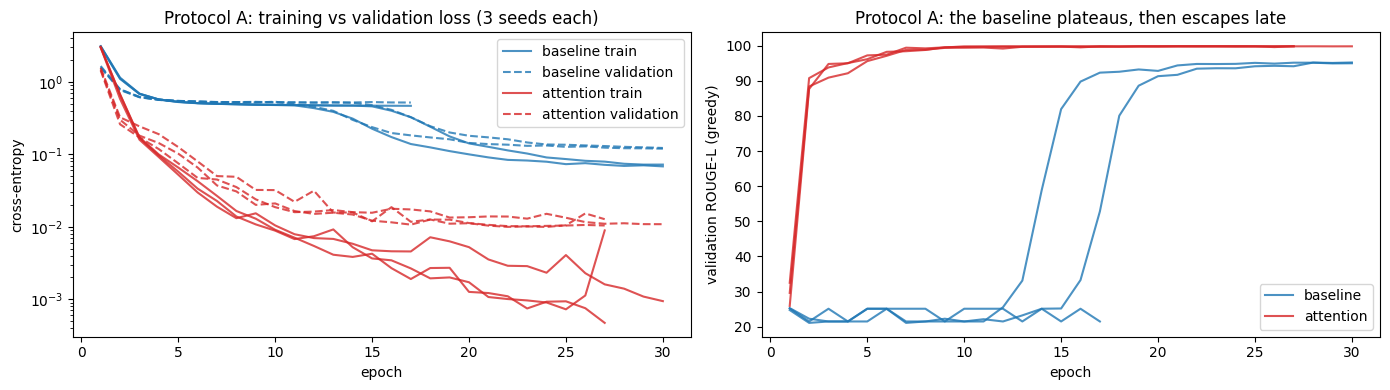

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
colors = {"baseline": "tab:blue", "attention": "tab:red"}
for pr in PROTOCOLS:
    for (p_, nm, sd), r in RUNS.items():
        if p_ != pr or pr != "A (30 epochs, patience 5)": continue
        h = pd.DataFrame(r["hist"]); first = sd == SEEDS[0]
        ax[0].plot(h.epoch, h.train_loss, color=colors[nm], alpha=.8, label=f"{nm} train" if first else None)
        ax[0].plot(h.epoch, h.val_familiar_loss, color=colors[nm], ls="--", alpha=.8, label=f"{nm} validation" if first else None)
        ax[1].plot(h.epoch, h.val_familiar_rougeL, color=colors[nm], alpha=.8, label=nm if first else None)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy"); ax[0].set_title("Protocol A: training vs validation loss (3 seeds each)"); ax[0].legend()
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation ROUGE-L (greedy)"); ax[1].set_title("Protocol A: the baseline plateaus, then escapes late"); ax[1].legend()
plt.tight_layout(); fig.savefig(f"{RESULTS_DIR}/figures/learning_curves_protocol_A.png", dpi=130); plt.show()

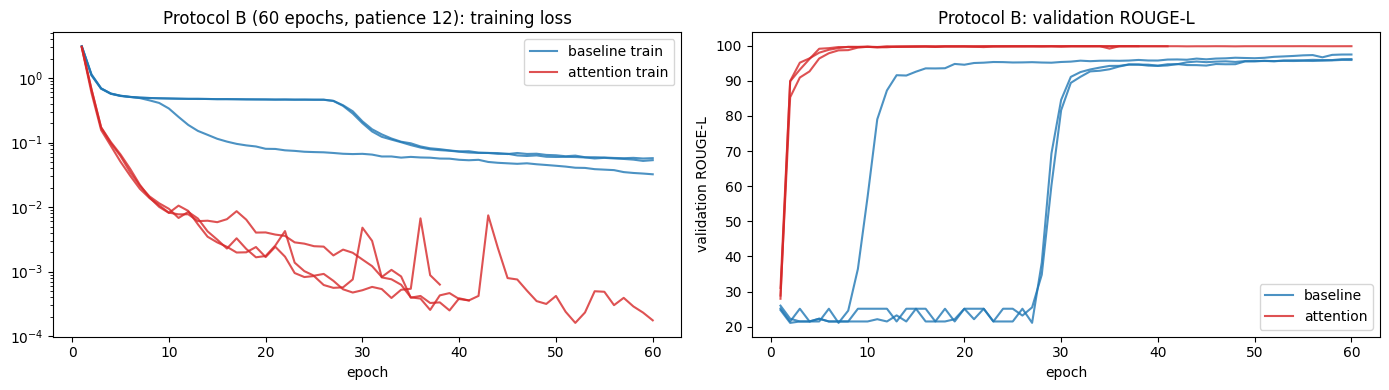

In [ ]:
# Create two plots
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
colors = {"baseline": "tab:blue", "attention": "tab:red"}

# Plot results for Protocol A
for pr in PROTOCOLS:
    for (p_, nm, sd), r in RUNS.items():
        if p_ != pr or pr != "A (30 epochs, patience 5)":
            continue
        h = pd.DataFrame(r["hist"])
        first = sd == SEEDS[0]

        # Training and validation loss
        ax[0].plot(
            h.epoch, h.train_loss, color=colors[nm],
            alpha=.8, label=f"{nm} train" if first else None)
        ax[0].plot(
            h.epoch, h.val_familiar_loss, color=colors[nm],
            ls="--", alpha=.8,
            label=f"{nm} validation" if first else None)
        # Validation ROUGE-L
        ax[1].plot(
            h.epoch, h.val_familiar_rougeL,
            color=colors[nm], alpha=.8,
            label=nm if first else None)

# Loss plot
ax[0].set_yscale("log")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("cross-entropy")
ax[0].set_title(
    "Protocol A: training vs validation loss (3 seeds each)")
ax[0].legend()

# ROUGE-L plot
ax[1].set_xlabel("epoch")
ax[1].set_ylabel("validation ROUGE-L (greedy)")
ax[1].set_title("Protocol A: the baseline plateaus, then escapes late")
ax[1].legend()

# Save and show
plt.tight_layout()
fig.savefig(
    f"{RESULTS_DIR}/figures/learning_curves_protocol_A.png", dpi=130)
plt.show()

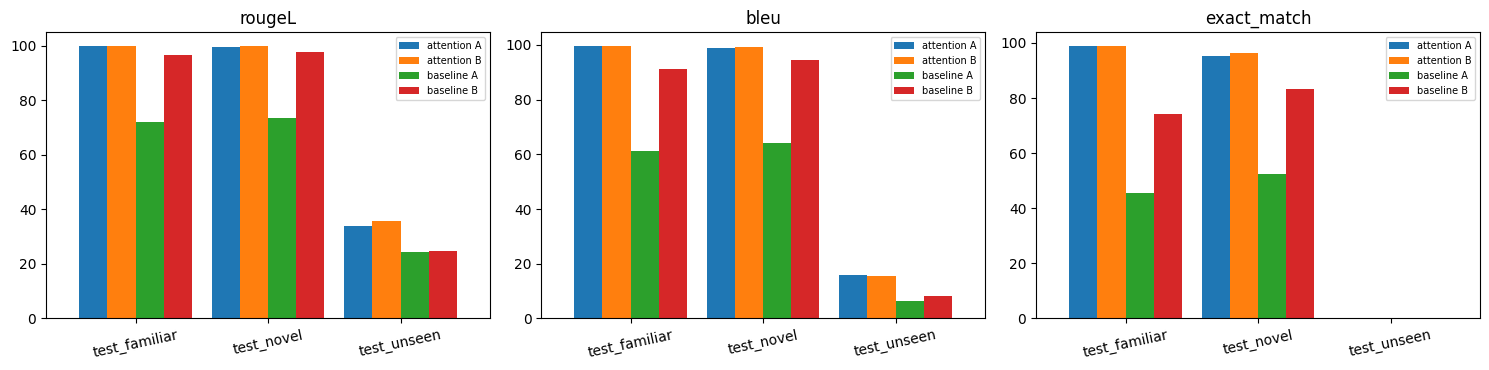

In [ ]:
# Create three comparison plots
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, m in zip(ax, ["rougeL", "bleu", "exact_match"]):
    # Calculate average scores for each model and protocol
    piv = (
        ALL.groupby(["split", "model", "protocol"])[m]
        .mean()
        .unstack(["model", "protocol"])
        .loc[["test_familiar", "test_novel", "test_unseen"]])

    # Shorten the column names
    piv.columns = [f"{a_} {p_[0]}" for a_, p_ in piv.columns]

    # Plot the results
    piv.plot.bar(ax=a, rot=12, width=.85)
    a.set_title(m)
    a.set_xlabel("")
    a.legend(fontsize=7)

# Save and display
plt.tight_layout()
fig.savefig(
    f"{RESULTS_DIR}/figures/comparison.png",
    dpi=130) plt.show()

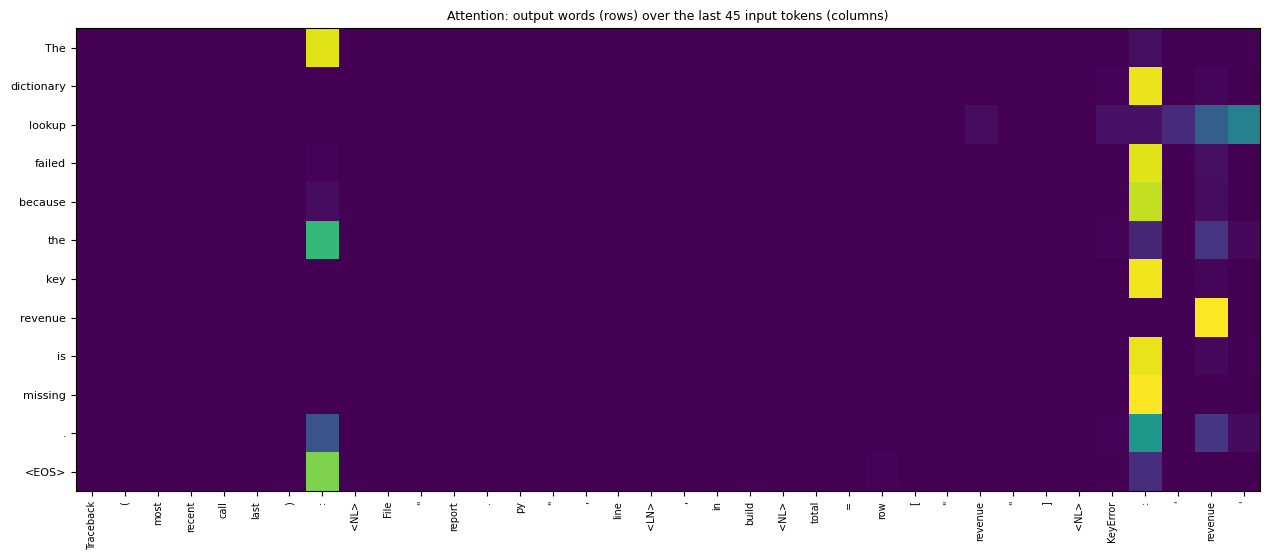

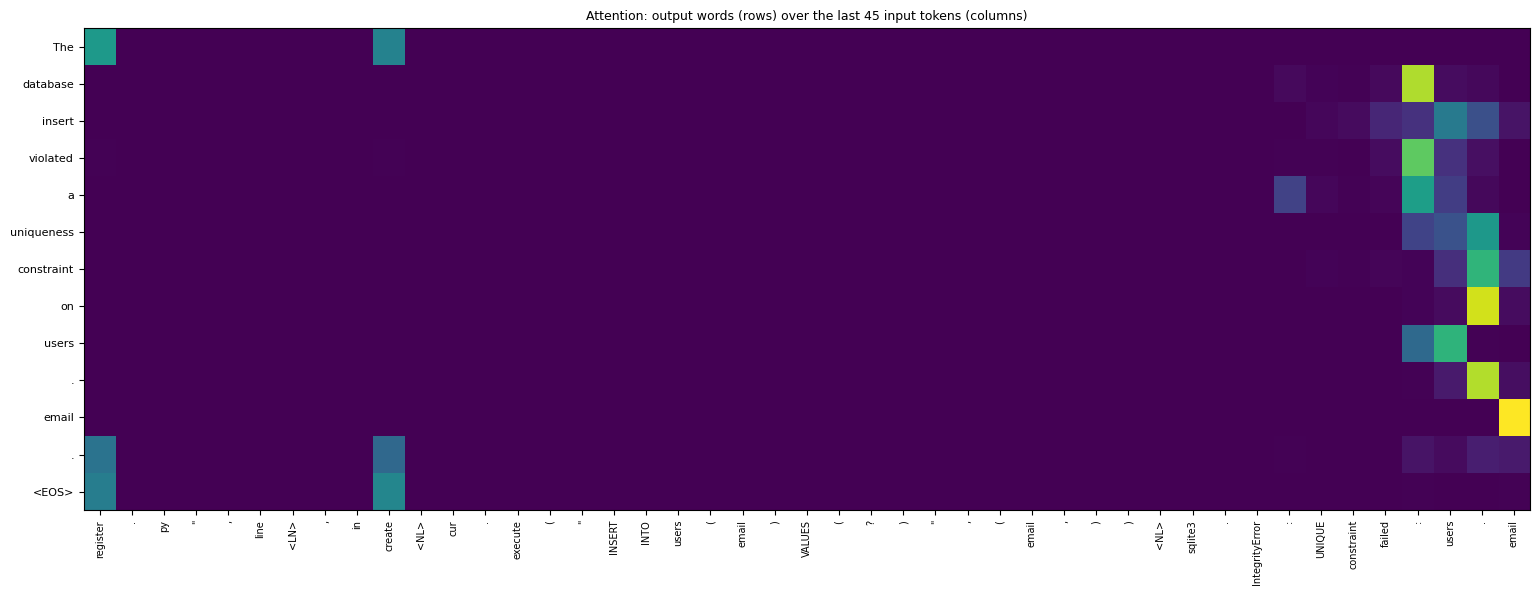

In [ ]:
def show_attention(model, text):
    # Prepare the traceback
    toks = tokenize_source(
        ensure_traceback_header(text),
        cfg["normalize_line_numbers"])
    mp = slot_map(toks, sv)

    shown = toks[-cfg["max_src_len"]:]
    ids, _ = sv.encode(apply_map(shown, mp))

    # Generate the explanation and attention weights
    out, att = model.generate(
        torch.tensor([ids]),
        torch.tensor([len(ids)]),
        max_len=40,
        return_attention=True)

    # Get the generated words
    words = restore(
        tv.decode(out[0].tolist(), stop_at_eos=False), mp)[:att.shape[1]]

    # Keep the last 45 input tokens
    A = att[0].numpy()[:len(words), -45:]
    xt = shown[-45:]

    # Create the attention heatmap
    fig, ax = plt.subplots(
        figsize=(min(18, .3 * len(xt) + 2),.35 * len(words) + 1.5))

    ax.imshow(A, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(xt)))
    ax.set_xticklabels(xt, rotation=90, fontsize=7)
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(words, fontsize=8)
    ax.set_title(
        "Attention: output words (rows) over the last 45 input tokens (columns)",
        fontsize=9)
    plt.tight_layout()
    return fig
# Select an attention model
best_att = next(
    (r["model"] for k, r in RUNS.items() if k[1] == "attention"),None)

# Example 1: KeyError
tb1 = (
    'Traceback (most recent call last):\n'
    '  File "report.py", line 41, in build\n'
    '    total = row["revenue"]\n'
    "KeyError: 'revenue'")

# Example 2: SQLite error
tb2 = (
    'Traceback (most recent call last):\n'
    '  File "register.py", line 18, in create\n'
    '    cur.execute("INSERT INTO users (email) VALUES (?)", (email,))\n'
    'sqlite3.IntegrityError: UNIQUE constraint failed: users.email')

# Generate and save the attention plots
if best_att is not None:
    for k, t in enumerate([tb1, tb2]):
        fig = show_attention(best_att, t)
        fig.savefig(
            f"{RESULTS_DIR}/figures/attention_example{k}.png",
            dpi=130)plt.show()

## 14. Real Inference Examples

We load the best attention model from `../checkpoints/codenarrator_best.pt`. The checkpoint contains the model weights, vocabularies and configuration. The model was selected using validation results.

We run the model on CPU in evaluation mode. **All explanations are generated by the model**, not written manually.

The script `tools/make_inference_examples.py` tests 28 examples, including simple errors, full tracebacks, unusual identifiers and unseen error types.

The results, inference times and human review are saved in `../results/inference_examples.csv`.

In [ ]:
# Load the best model on CPU
summarizer = Summarizer(
    f"{CKPT_DIR}/codenarrator_best.pt", "cpu")

print(
    "loaded:",
    "attention" if summarizer.ck["use_attention"] else "baseline",
    "| params", f"{summarizer.model.num_parameters():,}",
    "| training mode:", summarizer.model.training)

# Test examples
CASES = [
    ("single line", "ZeroDivisionError: division by zero"),
    ("single line", "NameError: name 'total_price' is not defined"),
    ("single line", "AttributeError: 'NoneType' object has no attribute 'append'"),

    ("multi-line",
     'Traceback (most recent call last):\n'
     '  File "pipeline.py", line 82, in run_pipeline\n'
     '    data = load_records("customers.csv")\n'
     '  File "loader.py", line 27, in load_records\n'
     '    return pd.read_csv("customers.csv")\n'
     "FileNotFoundError: [Errno 2] No such file or directory: 'customers.csv'"),

    ("unseen identifier",
     'Traceback (most recent call last):\n'
     '  File "inventory.py", line 7, in stock\n'
     '    return row["qty_in_stock_2024"]\n'
     "KeyError: 'qty_in_stock_2024'"),

    ("unseen exception class",
     'Traceback (most recent call last):\n'
     '  File "pay.py", line 40, in charge\n'
     '    raise PaymentError("card declined")\n'
     'PaymentError: card declined'),

    ("unsupported family",
     'Traceback (most recent call last):\n'
     '  File "queue.py", line 12, in drain\n'
     '    items.pop()\n'
     'IndexError: pop from empty list'),]

# Generate explanations for each example
rows = []

for kind, text in CASES:
    t0 = time.perf_counter()
    out = summarizer(text)
    ms = (time.perf_counter() - t0) * 1000

    # Check if the model gives the same answer twice
    again = summarizer(text)

    rows.append({
        "kind": kind,
        "last_line": text.splitlines()[-1],
        "output": out,
        "ms": round(ms, 1),
        "deterministic": out == again,
        "warnings": " | ".join(summarizer.warnings(text))})

# Display the results
pd.set_option("display.max_colwidth", 95, "display.width", 250)
pd.DataFrame(rows)

loaded: attention | params 2,800,747 | training mode: False


,kind,last_line,output,ms,deterministic,warnings
0,single line,ZeroDivisionError: division by zero,The calculation failed because the divisor was zero.,12.4,True,
1,single line,NameError: name 'total_price' is not defined,The program referenced total_price before defining it.,15.8,True,
2,single line,AttributeError: 'NoneType' object has no attribute 'append',The application tried to access the currency attribute on a NoneType object that does not p...,25.4,True,
3,multi-line,FileNotFoundError: [Errno 2] No such file or directory: 'customers.csv',The application could not read customers.csv because the file does not exist.,35.8,True,
4,unseen identifier,KeyError: 'qty_in_stock_2024',The dictionary lookup failed because the key qty_in_stock_2024 is missing.,24.9,True,
5,unseen exception class,PaymentError: card declined,The card operation failed because the card table is missing.,24.6,True,The model never saw the exception type PaymentError during training; the summary is probabl...
6,unsupported family,IndexError: pop from empty list,The application attempted to access a pop position that does not exist.,27.1,True,


In [ ]:
# Load the review of 28 inference examples
rev = pd.read_csv("../results/inference_examples.csv")
# Count results for each verdict
print(rev.verdict.value_counts().to_string(), "\n")
# Count verdicts for each type of error
print(
    rev.groupby("kind").verdict
    .value_counts()
    .unstack(fill_value=0).to_string(),"\n")

# Show inference speed and consistency
print(
    "median CPU latency per request: %.1f ms | all outputs deterministic: %s"
    % (
        rev.latency_ms.median(),
        bool(rev.deterministic.dropna().all())
    )
)

# Display examples that were not fully correct
rev[rev.verdict != "correct"][
    ["case", "output", "verdict", "note"]
].reset_index(drop=True)

verdict
correct              17
incorrect             8
partially correct     3 

verdict             correct  incorrect  partially correct
kind                                                     
edge_case                 2          2                  0
multiline                 8          0                  0
single_line               4          1                  1
unsupported_family        0          5                  0
unusual_identifier        3          0                  2 

median CPU latency per request: 29.1 ms | all outputs deterministic: True


,case,output,verdict,note
0,key_error_1line,The configuration lookup failed because the key username is missing.,partially correct,"Key name copied correctly, but ""configuration lookup"" is a guess: three KeyError families e..."
1,attribute_error_1line,The application tried to access the currency attribute on a NoneType object that does not p...,incorrect,"Hallucinated attribute ""currency"" instead of ""append"": ""append"" is a known source word but ..."
2,hyphen_file,The application could not read q1.csv because the file does not exist.,partially correct,"Right error, wrong file name: ""sales-2024-q1.csv"" is split at hyphens and only ""q1.csv"" is ..."
3,old_sklearn_import,The application could not import train_test_split from the cross_validation module.,partially correct,"Name copied, but the module is ""cross_validation"" instead of ""sklearn.cross_validation"" (do..."
4,unseen_pop_empty,The application attempted to access a pop position that does not exist.,incorrect,"Unsupported family: fluent but wrong (""pop position does not exist""); the model has no summ..."
5,unseen_array_truth,The application could not retrieve the result because the concurrent task was cancelled.,incorrect,Unsupported family: unrelated sentence about a cancelled concurrent task.
6,unseen_custom_exception,The card operation failed because the card table is missing.,incorrect,"Unseen exception class: invents ""the card table is missing"" (hallucination). The API warns ..."
7,unseen_unicode_error,The function UTF was called with more arguments than it accepts.,incorrect,Unsupported family: unrelated sentence.
8,unseen_zip_error,The application attempted to use a file that was already closed.,incorrect,Unsupported family: unrelated sentence about a closed file.
9,chained_exception,The application could not convert config to an integer.,incorrect,Chained tracebacks were never seen: the model mixes the first exception (int conversion) wi...


In [ ]:
# Test the model with a custom traceback
my_traceback = """Traceback (most recent call last):
  File "app.py", line 12, in main
    price = items[3]
IndexError: list index out of range"""
# Generate the explanation
print(summarizer(my_traceback))

# Display possible warnings
print("warnings:", summarizer.warnings(my_traceback))

The application attempted to access a list position that does not exist.
warnings: []


## 15. Limitations and conclusion

In [ ]:
# Calculate mean and standard deviation
def mean_of(protocol, model, split, metric):
    sub = ALL[
        (ALL.protocol == protocol) &
        (ALL.model == model) &
        (ALL.split == split)
    ][metric]

    if len(sub):
        return sub.mean(), sub.std()

    return float("nan"), float("nan")
# Compare baseline and attention results
for pr in PROTOCOLS:
    print(f"--- protocol {pr}")

    for sp in ["test_familiar", "test_novel", "test_unseen"]:

        # ROUGE-L scores
        b = mean_of(pr, "baseline", sp, "rougeL")
        a = mean_of(pr, "attention", sp, "rougeL")

        # Exact match scores
        be = mean_of(pr, "baseline", sp, "exact_match")
        ae = mean_of(pr, "attention", sp, "exact_match")

        print(
            f"{sp:14s} "
            f"ROUGE-L baseline {b[0]:5.1f} ± {b[1]:4.1f} | "
            f"attention {a[0]:5.1f} ± {a[1]:4.1f}   ||  "
            f"exact match baseline {be[0]:5.1f} | "
            f"attention {ae[0]:5.1f}")

--- protocol A (30 epochs, patience 5)
test_familiar  ROUGE-L baseline  71.8 ± 40.4 | attention  99.8 ±  0.0   ||  exact match baseline  45.6 | attention  98.9
test_novel     ROUGE-L baseline  73.3 ± 40.6 | attention  99.6 ±  0.0   ||  exact match baseline  52.3 | attention  95.4
test_unseen    ROUGE-L baseline  24.2 ±  3.7 | attention  33.8 ±  4.2   ||  exact match baseline   0.0 | attention   0.0
--- protocol B (60 epochs, patience 12)
test_familiar  ROUGE-L baseline  96.5 ±  0.8 | attention  99.8 ±  0.0   ||  exact match baseline  74.3 | attention  98.9
test_novel     ROUGE-L baseline  97.5 ±  0.2 | attention  99.7 ±  0.0   ||  exact match baseline  83.3 | attention  96.3
test_unseen    ROUGE-L baseline  24.5 ±  1.1 | attention  35.7 ±  3.0   ||  exact match baseline   0.0 | attention   0.0


### What the Results Show

- **Good performance on familiar errors:** The attention model generates almost all reference explanations correctly, including new identifiers thanks to copy slots.

- **Attention vs. baseline:** The attention model learns faster and more consistently. The baseline sometimes gets stuck during training, especially with Protocol A (30 epochs). With Protocol B (60 epochs), it improves but still performs slightly worse than attention.

- **Poor performance on unseen error families:** Both models struggle with errors they have never seen during training. They often generate fluent but incorrect explanations (ROUGE-L around 25–35, exact match 0).

### Limitations

- **Synthetic data:** The models were trained on generated examples covering 104 error families. The results do not guarantee reliability on real-world errors.

- **Evaluation metrics:** Each input has only one reference explanation, so ROUGE, BLEU and exact match may penalize other correct explanations.

- **Copy slots:** They help preserve unknown identifiers but do not handle every case. Some known source words that are missing from the target vocabulary, hyphenated filenames and module paths may be reproduced incorrectly.

- **Unseen errors:** The models can generate confident but incorrect explanations for unknown exception classes or unsupported error families.

- **Complex tracebacks:** Chained exceptions were not included in training, so the models may misunderstand them.

- **Training stability:** The baseline sometimes needs more epochs to improve, and its performance depends more on the random seed.

Overall, **attention improves learning speed and consistency**, but both models have limitations when handling unfamiliar errors.